(mmm_funnel_one_vs_two_stage)=
# One-Stage vs Two-Stage Funnel Models: When Does Joint Estimation Matter?

A funnel-aware MMM splits the effect of an upper-funnel channel, such as video, into two paths. One goes straight to sales. The other goes through lower-funnel demand: people who saw the video and later search for the brand. Estimating this takes two equations:

- a **mediator equation**: how upper-funnel spend changes lower-funnel demand;
- an **outcome equation**: how upper-funnel spend and lower-funnel demand change sales.

A common way to estimate them fits the two equations separately (two-stage) and puts an observed lower-funnel series, such as branded search volume, straight into the sales equation. That approach makes two choices at once:

1. it treats the observed series as the thing that drives sales;
2. it fits the two equations separately instead of together.

This notebook separates the two choices and tests each against a joint (one-stage) model, on synthetic data where the true effects are known. The first choice turns out to matter much more than the second.

```{important}
Most of the data here are sampled from the one-stage model itself, so that model is correctly specified by construction. To balance this, the notebook also tests a reverse scenario in which the common two-stage approach is the correctly specified one.
```

```{note}
People also call a funnel with two layers (upper $\to$ lower $\to$ sales) a "two-stage funnel". That describes the causal structure. In this notebook, "two-stage" and "one-stage" describe how the model is estimated: two separate fits chained together, or one joint fit. All models here share the same two-layer structure.
```

## Prepare Notebook

In [1]:
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pymc.dims as pmd
import pytensor.tensor as pt
import xarray as xr
from pydantic import InstanceOf
from pymc import do
from pymc_extras.prior import Prior
from scipy import stats

from pymc_marketing.mmm import (
    AdstockTransformation,
    GeometricAdstock,
    LogisticSaturation,
    SaturationTransformation,
)
from pymc_marketing.mmm.additive_effect import DataVarMuEffect, IncrementalitySpec
from pymc_marketing.mmm.mmm import MMM

FIG_WIDTH = 10
FIG_HEIGHT = 6
COLOR_TRUE = "black"
COLOR_MEASURED = "#52514e"

MODELS = ["two_stage_observed", "two_stage_predicted", "one_stage"]
MODEL_LABELS = {
    "two_stage_observed": "Two-stage, observed mediator",
    "two_stage_predicted": "Two-stage, predicted mediator",
    "one_stage": "One-stage (joint)",
}
MODEL_COLORS = {
    "two_stage_observed": "#2a78d6",
    "two_stage_predicted": "#eb6834",
    "one_stage": "#1baf7a",
}
PATHS = ["direct", "indirect", "total"]
PATH_LABELS = {
    "direct": "Direct (U -> Y)",
    "indirect": "Indirect (U -> D -> Y)",
    "total": "Total upper-funnel effect",
}

warnings.filterwarnings("ignore", category=FutureWarning)

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [FIG_WIDTH, FIG_HEIGHT]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

In [2]:
seed: int = sum(map(ord, "funnel"))
rng: np.random.Generator = np.random.default_rng(seed=seed)

## One-stage and two-stage models

### Two-stage

Stage 1 fits the mediator equation on lower-funnel data alone. Stage 2 fits the outcome equation on sales, taking a lower-funnel series as a fixed input. To get the indirect effect, you chain them: stage 1 says how much demand upper spend created, and stage 2 says how much sales that demand produced. Pairing posterior draw $i$ of stage 1 with draw $i$ of stage 2 carries stage-1 uncertainty into the result. Each stage is a small model that you can fit and check on its own, and a problem in one stage cannot leak into the other, which is why this workflow is popular.

### One-stage

Both equations go into one model with two likelihoods, one for lower-funnel data and one for sales, and are fit together. This is what the `MeasuredMediatorEffect` in {ref}`mmm_funnel_mueffect` does. Sales data can now inform the mediator equation, and the posterior tracks how the parameters of the two equations depend on each other.

The diagrams use the variables of this notebook: upper-funnel spend $U$, a driver of lower-funnel demand that does not affect sales $C$, lower-funnel demand $D$ (never observed), an observed lower-funnel signal $M$ such as branded search volume (a noisy reading of $D$), and sales $Y$. Gray nodes are observed data; white nodes are latent.

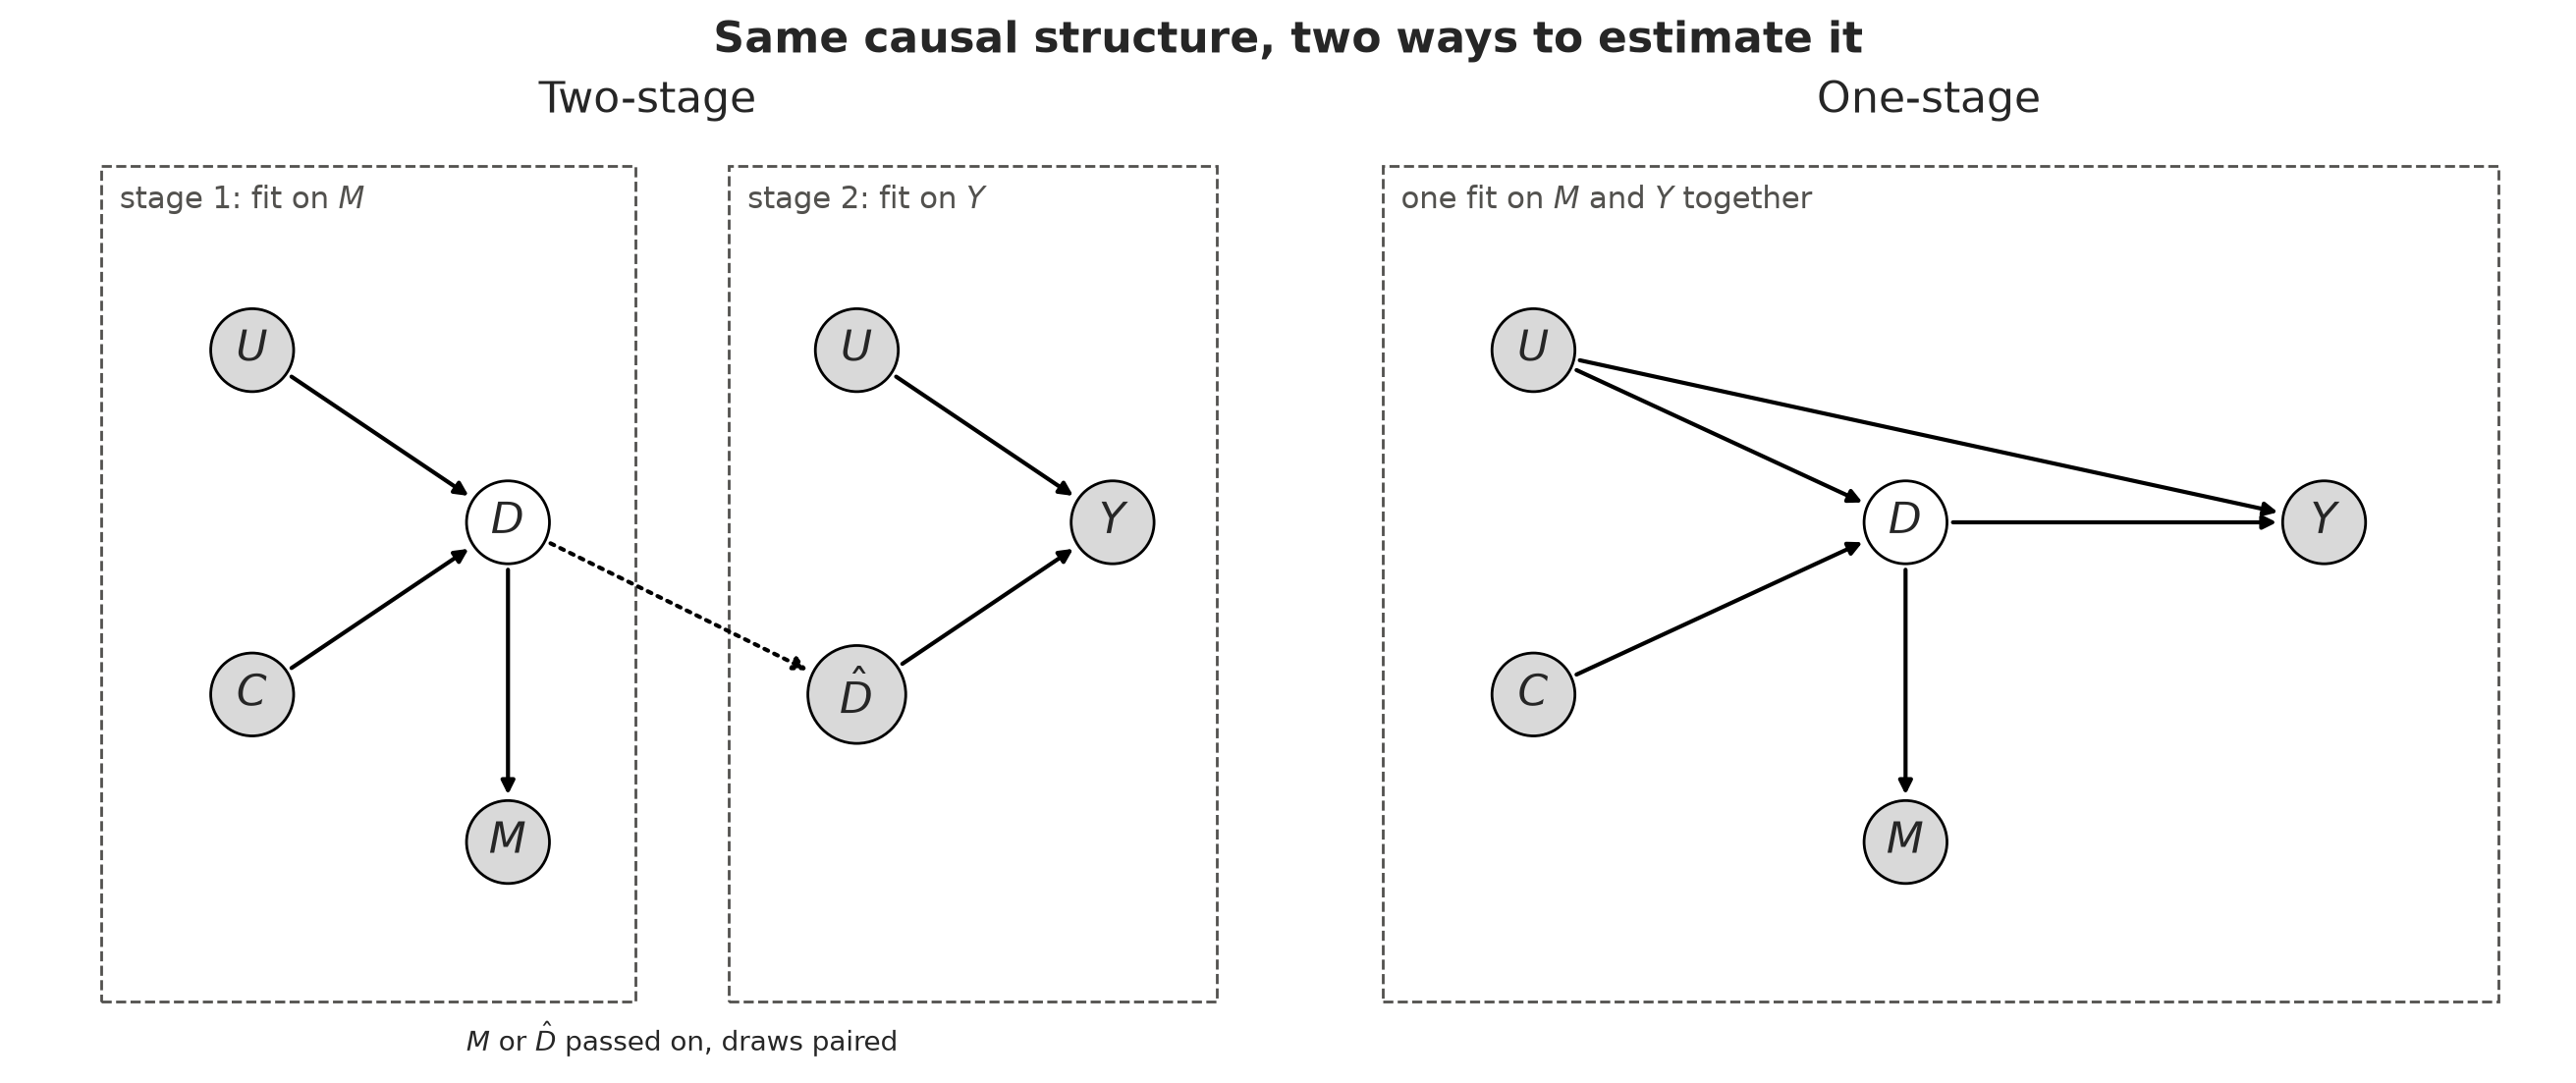

In [3]:
def draw_dag(ax, nodes, edges, title):
    """Draw a small causal diagram; observed nodes in gray, latent in white."""
    artists = {}
    for name, (x, y, label, observed) in nodes.items():
        artists[name] = ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            fontsize=16,
            bbox={
                "boxstyle": "circle,pad=0.45",
                "facecolor": "#d9d9d9" if observed else "white",
                "edgecolor": "black",
            },
        )
    for start, end, style in edges:
        ax.annotate(
            "",
            xy=(0.5, 0.5),
            xycoords=artists[end],
            xytext=(0.5, 0.5),
            textcoords=artists[start],
            arrowprops={
                "arrowstyle": "-|>",
                "linestyle": style,
                "linewidth": 1.5,
                "color": "black",
                "patchA": artists[start].get_bbox_patch(),
                "patchB": artists[end].get_bbox_patch(),
                "shrinkA": 2,
                "shrinkB": 2,
            },
        )
    ax.set(xlim=(-0.6, 4.8), ylim=(-0.9, 2.9), title=title)
    ax.axis("off")


def stage_box(ax, x0, y0, x1, y1, label):
    """Dashed frame marking which data a fit sees."""
    ax.add_patch(
        plt.Rectangle(
            (x0, y0), x1 - x0, y1 - y0, fill=False, linestyle="--", color="#52514e"
        )
    )
    ax.text(x0 + 0.08, y1 - 0.08, label, va="top", fontsize=11, color="#52514e")


fig, (ax_two, ax_one) = plt.subplots(1, 2, figsize=(FIG_WIDTH * 1.3, FIG_HEIGHT * 0.9))

draw_dag(
    ax_two,
    nodes={
        "U1": (0.4, 2.0, "$U$", True),
        "C": (0.4, 0.6, "$C$", True),
        "D": (1.5, 1.3, "$D$", False),
        "M": (1.5, 0.0, "$M$", True),
        "U2": (3.0, 2.0, "$U$", True),
        "Dhat": (3.0, 0.6, r"$\hat D$", True),
        "Y": (4.1, 1.3, "$Y$", True),
    },
    edges=[
        ("U1", "D", "-"),
        ("C", "D", "-"),
        ("D", "M", "-"),
        ("U2", "Y", "-"),
        ("Dhat", "Y", "-"),
        ("D", "Dhat", ":"),
    ],
    title="Two-stage",
)
stage_box(ax_two, -0.25, -0.65, 2.05, 2.75, "stage 1: fit on $M$")
stage_box(ax_two, 2.45, -0.65, 4.55, 2.75, "stage 2: fit on $Y$")
ax_two.text(
    2.25, -0.85, r"$M$ or $\hat D$ passed on, draws paired", ha="center", fontsize=10
)

draw_dag(
    ax_one,
    nodes={
        "U": (0.4, 2.0, "$U$", True),
        "C": (0.4, 0.6, "$C$", True),
        "D": (2.0, 1.3, "$D$", False),
        "M": (2.0, 0.0, "$M$", True),
        "Y": (3.8, 1.3, "$Y$", True),
    },
    edges=[
        ("U", "D", "-"),
        ("C", "D", "-"),
        ("D", "M", "-"),
        ("D", "Y", "-"),
        ("U", "Y", "-"),
    ],
    title="One-stage",
)
stage_box(ax_one, -0.25, -0.65, 4.55, 2.75, "one fit on $M$ and $Y$ together")
fig.suptitle(
    "Same causal structure, two ways to estimate it", fontsize=16, fontweight="bold"
);

**Caption:** In the two-stage fit (left), stage 1 never sees sales $Y$, and stage 2 treats its lower-funnel input as known: either the observed signal $M$ or stage-1 predicted demand $\hat D$. In the one-stage fit (right), $M$ and $Y$ are both likelihoods of one model, so information flows from sales back to the mediator equation.

## Are one-stage and two-stage the same?

In general, no. Write $\theta_1$ for the parameters of the mediator equation and $\theta_2$ for the rest of the model. With lower-funnel data $M$ and sales $Y$, the joint posterior is

$$
p(\theta_1, \theta_2 \mid M, Y) \;\propto\; p(M \mid \theta_1)\; p(Y \mid \theta_1, \theta_2, M)\; p(\theta_1)\, p(\theta_2).
$$

The sales likelihood $p(Y \mid \theta_1, \theta_2, M)$ is where the two approaches part ways. When sales depend on $\theta_1$, sales data carry information about the mediator equation. A joint fit uses that information; a two-stage fit cannot, because stage 1 never sees sales.

The two coincide in one special setup: the outcome equation uses the observed series $M$ itself as a regressor, and no parameter appears in both equations. Sales then no longer depend on $\theta_1$, the posterior splits into two independent pieces,

$$
p(\theta_1, \theta_2 \mid M, Y) = p(\theta_1 \mid M)\; p(\theta_2 \mid Y, M),
$$

and a joint fit gives exactly the same answer as two separate fits with paired draws.

That setup assumes sales respond to exactly the number in your dataset, which is rarely how a funnel works. Sales respond to demand: people who saw the video and now search for the brand. Branded search volume is a noisy reading of that demand. Once the model says sales respond to demand rather than to its reading, sales carry information about $\theta_1$ and the two approaches differ. A parameter shared across the two equations, or lower-funnel data missing in some weeks, have the same effect.

Outside that setup, a two-stage fit is a deliberate simplification: it stops sales data from informing the mediator equation, which keeps the stages independent but throws away information. The rest of the notebook measures what that costs, on data where the truth is known.

## Data generating process

We reuse the data generating process of {ref}`mmm_funnel_mueffect` without changes, including its seed and true parameters:

- `upper_spend` ($U$): the upper-funnel channel.
- `lower_control` ($C$): a driver of lower-funnel demand that does not enter the sales equation.
- lower-funnel demand ($D$, latent): $D_t = \beta_0 + \gamma C_t + f_{u\to l}(U_t)$.
- `lower_spend` ($M$): the observed lower-funnel signal, a noisy measurement of demand, $M_t \sim \text{TruncatedNormal}(D_t, \sigma_M, \text{lower}=0)$.
- the target ($Y$): $Y_t \sim \text{Normal}\big(\alpha + f_{\text{direct}}(U_t) + f_{l\to y}(D_t),\ \sigma_Y\big)$.

Each $f$ is a geometric adstock followed by a logistic saturation. Sales respond to demand $D$, not to its measurement $M$. The column is called `lower_spend` in {ref}`mmm_funnel_mueffect`, but in this world it behaves like branded search volume: a reading of demand that does not move sales by itself. We keep the column name and call it the lower-funnel signal in the text.

`lower_control` moves demand but not sales. That gives demand some variation that upper spend does not explain, which helps every model tell the two paths apart. Without it, the reliability check below would be close to zero, and the common approach's bias would be larger.

### The one-stage component

The data generator and the one-stage model share the `MeasuredMediatorEffect` from {ref}`mmm_funnel_mueffect`. It is a {class}`~pymc_marketing.mmm.additive_effect.DataVarMuEffect` whose `create_effect` builds the demand equation, adds a second likelihood for the observed signal, and returns the demand $\to$ target contribution. That notebook walks through it step by step.

In [4]:
class MeasuredMediatorEffect(DataVarMuEffect):
    """Upper- to lower-funnel mediation with its own likelihood.

    Encodes the indirect path ``upper_spend -> hub -> target`` as an additive
    effect on the target mean, while jointly fitting lower-funnel spend through
    a second (truncated normal) likelihood.
    """

    data_vars: list[str] = ["lower_spend", "lower_control"]
    prefix: str = "mediator"
    hub_adstock: InstanceOf[AdstockTransformation]
    hub_saturation: InstanceOf[SaturationTransformation]
    contribution_adstock: InstanceOf[AdstockTransformation]
    contribution_saturation: InstanceOf[SaturationTransformation]

    def to_dict(self) -> dict:
        """Serialize the effect (media transforms delegate to their own dicts)."""
        return {
            "prefix": self.prefix,
            "data_vars": list(self.data_vars),
            "hub_adstock": self.hub_adstock.to_dict(),
            "hub_saturation": self.hub_saturation.to_dict(),
            "contribution_adstock": self.contribution_adstock.to_dict(),
            "contribution_saturation": self.contribution_saturation.to_dict(),
        }

    def incrementality_spec(self) -> IncrementalitySpec:
        """Let a spend counterfactual travel through the mediated path."""
        return IncrementalitySpec()

    def create_effect(self, mmm):
        """Build the measured-mediator subgraph and return its contribution."""
        model = mmm.model
        # Structural equation 1: upper spend and control create the mediator.
        parent_into_hub = self.hub_saturation.apply(
            self.hub_adstock.apply(mmm.scaled_channel("upper_spend"), core_dim="date"),
            core_dim="date",
        )
        baseline = pmd.HalfNormal(f"{self.prefix}_baseline", sigma=1.0)
        parent_coef = pmd.HalfNormal(f"{self.prefix}_parent_coef", sigma=1.0)
        hub = pmd.Deterministic(
            f"{self.prefix}_hub",
            baseline + parent_coef * model["lower_control"] + parent_into_hub,
        )
        # Second likelihood: observed lower-funnel spend measures the mediator.
        pmd.TruncatedNormal(
            f"{self.prefix}_measurement",
            mu=hub,
            sigma=pmd.HalfNormal(f"{self.prefix}_measurement_sigma", sigma=1.0),
            lower=0.0,
            observed=model["lower_spend"],
        )
        # Structural equation 2: mediator demand enters the target mean.
        return pmd.Deterministic(
            f"{self.prefix}_effect_contribution",
            self.contribution_saturation.apply(
                self.contribution_adstock.apply(hub, core_dim="date"),
                core_dim="date",
            ),
        )

Two small factories keep every model on the same transformation families and priors. The **hub** transforms belong to the mediator equation ($f_{u\to l}$) and the **contribution** transforms to the demand $\to$ target path ($f_{l\to y}$). The variable names are shared, so each model gets the same prior for the same quantity.

In [5]:
n_dates = 130
l_max = 8

date_range = pd.date_range(start="2021-01-04", freq="W-MON", periods=n_dates)


def hub_transforms():
    """Adstock + saturation for upper spend -> lower-funnel demand."""
    return {
        "hub_adstock": GeometricAdstock(l_max=l_max, prefix="adstock_hub"),
        "hub_saturation": LogisticSaturation(prefix="sat_hub"),
    }


def contribution_transforms():
    """Adstock + saturation for lower-funnel demand -> target."""
    return {
        "contribution_adstock": GeometricAdstock(
            l_max=l_max, prefix="adstock_contribution"
        ),
        "contribution_saturation": LogisticSaturation(prefix="sat_contribution"),
    }


def make_mmm_dataset(frame, data_vars=("lower_spend", "lower_control")):
    """Bundle upper spend plus extra series into the ``xr.Dataset`` the MMM reads."""
    dates = pd.to_datetime(frame["date"]).to_numpy()
    ds = {
        "media": xr.DataArray(
            frame[["upper_spend"]].to_numpy(dtype=float),
            dims=("date", "channel"),
            coords={"date": dates, "channel": ["upper_spend"]},
        )
    }
    for name in data_vars:
        ds[name] = xr.DataArray(
            frame[name].to_numpy(dtype=float), dims=("date",), coords={"date": dates}
        )
    return xr.Dataset(ds)

### Exogenous drivers and ground truth

As in {ref}`mmm_funnel_mueffect`, two nearly independent drivers come from a small LKJ model, and each structural equation has fixed true parameters.

In [6]:
t = np.arange(n_dates) / n_dates
cov_coords = {"date": date_range, "driver": ["upper_spend", "lower_control"]}

with pm.Model(coords=cov_coords) as covariates_model:
    t_data = pm.Data("t", t, dims=("date",))
    L, _, _ = pm.LKJCholeskyCov("L", n=2, eta=100, sd_dist=pm.Exponential.dist(lam=1.0))
    a = pm.Normal("a", mu=0, sigma=1, dims="driver")
    b = pm.Normal("b", mu=0, sigma=1, dims="driver")
    mu_cov = pm.Deterministic(
        "mu_cov", a + b * t_data[..., None], dims=("date", "driver")
    )
    x_raw = pm.MvNormal("x_raw", mu=mu_cov, chol=L, dims=("date", "driver"))
    x = pm.Deterministic("x", pt.softplus(x_raw), dims=("date", "driver"))

x_data = pm.draw(covariates_model.x, draws=1, random_seed=rng)

df = pd.DataFrame(
    {
        "date": date_range,
        "upper_spend": x_data[:, 0],
        "lower_control": x_data[:, 1],
        # Placeholders: the generative model draws the actual series below.
        "lower_spend": np.ones(n_dates),
        "y_dummy": np.ones(n_dates),
    }
)

true = {
    "intercept_contribution": 0.25,
    # direct path: upper -> target
    "adstock_alpha": 0.45,
    "saturation_lam": 4.0,
    "saturation_beta": 0.80,
    "y_sigma": 0.05,
    # mediator equation: upper -> lower-funnel demand
    "mediator_baseline": 0.15,
    "mediator_parent_coef": 0.25,
    "adstock_hub_alpha": 0.50,
    "sat_hub_lam": 2.5,
    "sat_hub_beta": 1.3,
    "mediator_measurement_sigma": 0.04,
    # lower-funnel path: lower demand -> target
    "adstock_contribution_alpha": 0.30,
    "sat_contribution_lam": 1.2,
    "sat_contribution_beta": 1.1,
}
true = {k: np.asarray(v, dtype=float) for k, v in true.items()}

### Forward simulation

We build the one-stage MMM on a dummy target, fix every parameter at its true value with {func}`~pymc.model.transform.do`, and forward-sample. Besides the target and the observed signal, we keep the latent demand $D$. The models never see it, but it lets us check them. A second pass with `upper_spend` set to zero gives the true contribution of upper spend through the mediator.

In [7]:
gen = MMM(
    date_column="date",
    target_column="y_dummy",
    channel_columns=["upper_spend"],
    adstock=GeometricAdstock(l_max=l_max),
    saturation=LogisticSaturation(),
    model_config={
        "intercept": Prior("Normal", mu=0.3, sigma=0.1),
        "likelihood": Prior("Normal", sigma=Prior("HalfNormal", sigma=0.1)),
    },
)
gen.add_mu_effect(
    MeasuredMediatorEffect(**hub_transforms(), **contribution_transforms())
)
gen.build_model(make_mmm_dataset(df), df["y_dummy"])
gen.add_original_scale_contribution_variable(
    var=["channel_contribution", "mediator_effect_contribution", "y"]
)

channel_dim_vars = {"adstock_alpha", "saturation_lam", "saturation_beta"}
gen.model = do(
    gen.model,
    {k: (true[k].reshape(1) if k in channel_dim_vars else true[k]) for k in true},
)

with gen.model:
    idata_gen = pm.sample_prior_predictive(
        draws=1,
        var_names=[
            "y_original_scale",
            "channel_contribution_original_scale",
            "mediator_effect_contribution_original_scale",
            "mediator_measurement",
            "mediator_hub",
        ],
        random_seed=rng,
    )
    # Counterfactual: no upper-funnel spend.
    pm.set_data({"channel_data": np.zeros((n_dates, 1))})
    idata_cf = pm.sample_prior_predictive(
        draws=1,
        var_names=["mediator_effect_contribution_original_scale", "mediator_hub"],
        random_seed=rng,
    )
    pm.set_data({"channel_data": df[["upper_spend"]].to_numpy()})

prior = idata_gen["prior"].sel(chain=0, draw=0)
prior_pp = idata_gen["prior_predictive"].sel(chain=0, draw=0)
prior_cf = idata_cf["prior"].sel(chain=0, draw=0)


def _series(ds, var):
    return ds[var].to_numpy().reshape(n_dates, -1)[:, 0]


df["y_obs"] = _series(prior, "y_original_scale")
df["lower_spend"] = _series(prior_pp, "mediator_measurement")
df["demand_true"] = _series(prior, "mediator_hub")
df["demand_no_upper_true"] = _series(prior_cf, "mediator_hub")
df["direct_true"] = _series(prior, "channel_contribution_original_scale")
df["indirect_true"] = _series(
    prior, "mediator_effect_contribution_original_scale"
) - _series(prior_cf, "mediator_effect_contribution_original_scale")
df["total_true"] = df["direct_true"] + df["indirect_true"]

# Drop the first ``l_max`` rows: the adstock transform needs a burn-in window.
df = df.tail(-l_max).reset_index(drop=True)

truth = {path: df[f"{path}_true"].to_numpy() for path in PATHS}
for path in PATHS:
    print(f"Mean true {path:8s} contribution: {truth[path].mean():.3f}")

/Users/francesco-pymclabs/code/pymc-marketing/.venv/lib/python3.12/site-packages/pytensor/link/numba/dispatch/basic.py:234: UserWarning: Numba will use object mode to run truncated_normal_rv{"(),(),(),()->()"}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [mediator_measurement, y]


Sampling: []


Mean true direct   contribution: 0.335
Mean true indirect contribution: 0.199
Mean true total    contribution: 0.534


### Mediator noise as a dial

Sales depend on demand $D$, not on its measurement $M$. So we can make $M$ noisier while keeping demand, sales, and every true effect fixed. We recover the standardized shock behind each observed value of $M$ and rescale it to a new $\sigma_M$, so all noise levels share the same shocks. At $\sigma_M = 0.04$, the value used in {ref}`mmm_funnel_mueffect`, this reproduces that notebook's data exactly.

In [8]:
sigma_source = float(true["mediator_measurement_sigma"])
demand = df["demand_true"].to_numpy()
shock_quantile = stats.truncnorm.cdf(
    df["lower_spend"],
    a=-demand / sigma_source,
    b=np.inf,
    loc=demand,
    scale=sigma_source,
)


def measure_demand(sigma_m: float) -> np.ndarray:
    # Observed lower-funnel spend at measurement noise ``sigma_m`` (same shocks).
    return stats.truncnorm.ppf(
        shock_quantile, a=-demand / sigma_m, b=np.inf, loc=demand, scale=sigma_m
    )


def data_at(sigma_m: float) -> pd.DataFrame:
    return df.assign(lower_spend=measure_demand(sigma_m))


np.testing.assert_allclose(measure_demand(sigma_source), df["lower_spend"])

sigma_grid = [0.04, 0.1, 0.2]

**Caption:** Latent lower-funnel demand $D$ (black) and its observed measurement $M$ (gray) at the three noise levels used in this notebook. Demand, the target, and every true effect are identical across panels.

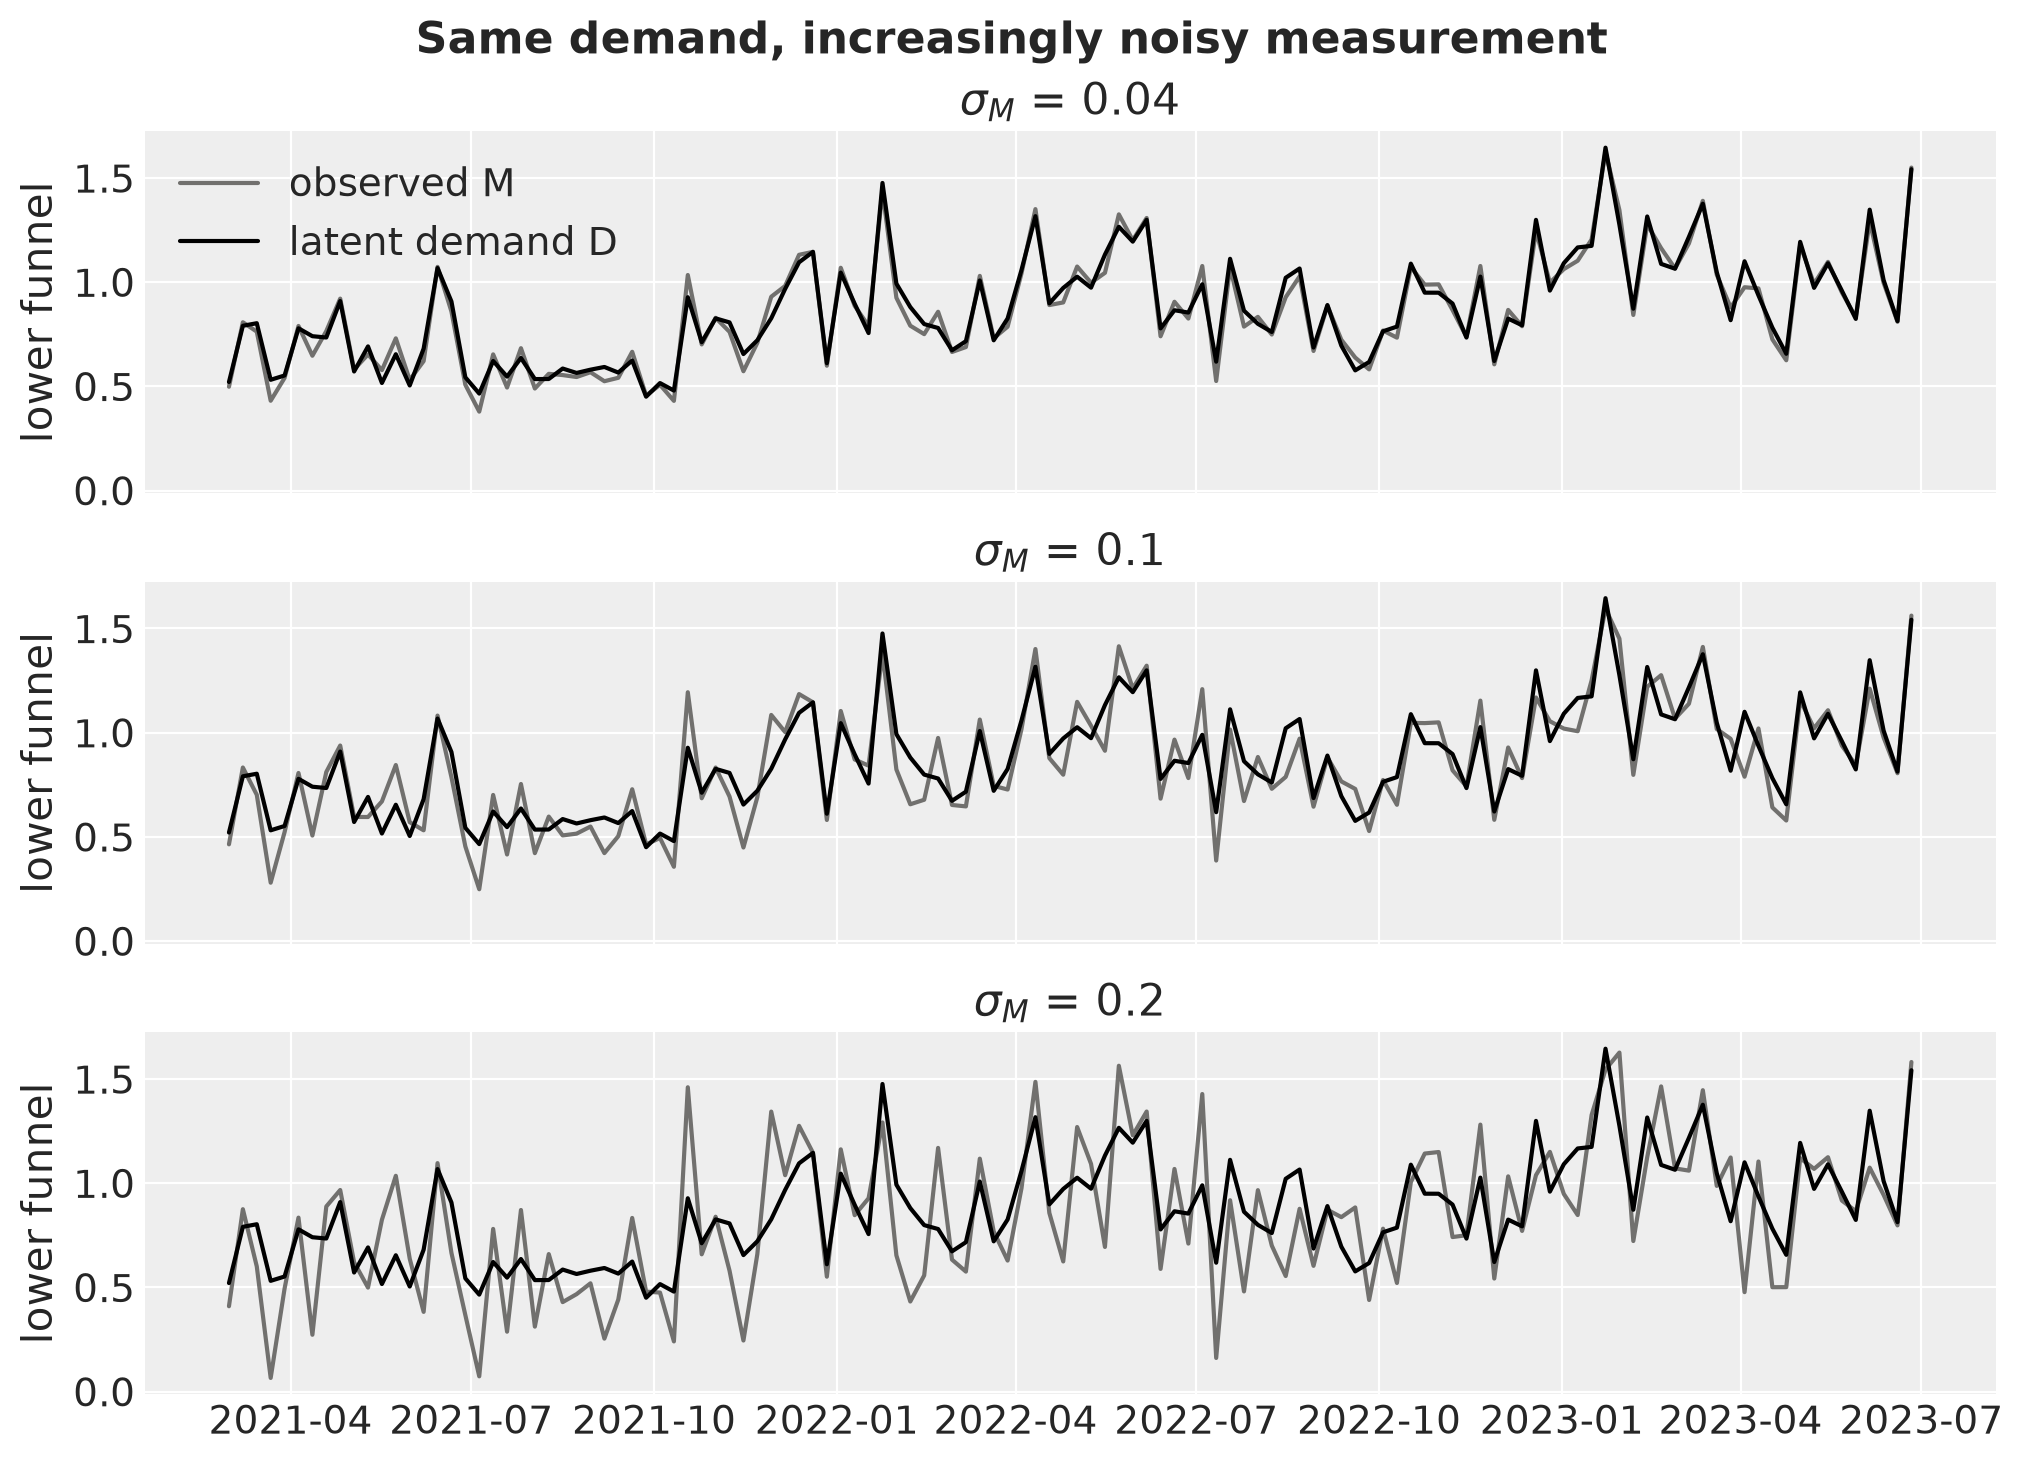

In [9]:
fig, axes = plt.subplots(
    nrows=len(sigma_grid),
    figsize=(FIG_WIDTH, FIG_HEIGHT * 1.2),
    sharex=True,
    sharey=True,
)
for ax, sigma_m in zip(axes, sigma_grid, strict=True):
    ax.plot(
        df["date"],
        measure_demand(sigma_m),
        color=COLOR_MEASURED,
        alpha=0.8,
        label="observed M",
    )
    ax.plot(df["date"], demand, color=COLOR_TRUE, label="latent demand D")
    ax.set(title=rf"$\sigma_M$ = {sigma_m}", ylabel="lower funnel")
axes[0].legend(loc="upper left")
fig.suptitle(
    "Same demand, increasingly noisy measurement", fontsize=16, fontweight="bold"
);

For a regression of sales on $U$ and $M$, what matters is the noise relative to the part of $D$ that upper spend does not explain, mostly the control-driven part $\gamma C_t$. That part varies much less than $D$ as a whole, so even modest measurement noise can drown it. Below is the share of that variation that is signal at each noise level.

In [10]:
upper_part = df["demand_true"] - df["demand_no_upper_true"]
residual_var = float(np.var(df["demand_true"] - upper_part))
print(f"Var(D):                     {np.var(df['demand_true']):.4f}")
print(f"Var(D not explained by U):  {residual_var:.4f}")
for sigma_m in sigma_grid:
    reliability = residual_var / (residual_var + sigma_m**2)
    print(
        f"sigma_M = {sigma_m:<4}: share of that variation that is signal = {reliability:.0%}"
    )

Var(D):                     0.0631
Var(D not explained by U):  0.0148
sigma_M = 0.04: share of that variation that is signal = 90%
sigma_M = 0.1 : share of that variation that is signal = 60%
sigma_M = 0.2 : share of that variation that is signal = 27%


## The three models

All three models use the same adstock and saturation families with the same priors. They differ only in what enters the outcome equation and in whether the two equations are fit together.

| Model | Mediator equation | Outcome equation | Indirect effect of $U$ |
|---|---|---|---|
| **Two-stage, observed mediator** | $M \sim \text{TN}(D_{\theta_1}, \sigma_M)$, fit alone | $Y \sim N(\alpha + f(U) + g(M), \sigma_Y)$ | $g(M) - g(M - \Delta)$ |
| **Two-stage, predicted mediator** | same stage 1 | $Y \sim N(\alpha + f(U) + g(\hat D), \sigma_Y)$, $\hat D$ = stage-1 posterior mean | $g(\hat D) - g(\hat D - \Delta)$ |
| **One-stage (joint)** | same equation, fit jointly | $Y \sim N(\alpha + f(U) + g(D_{\theta_1}), \sigma_Y)$ | $g(D) - g(D - \Delta)$ |

Here $g$ is the demand $\to$ target adstock and saturation, and $\Delta = f_{u\to l}(U)$ is the demand created by upper spend. In both two-stage models, $\Delta$ comes from stage 1 and is paired draw by draw with stage 2, so stage-1 uncertainty reaches every effect.

The observed-mediator model is the common approach from the introduction, and the special setup from the previous section: the observed signal goes straight into the outcome equation. Fitting it jointly would give the same posterior, so any error it makes comes from treating the signal as the cause, not from fitting in two stages. When the signal does drive sales, it is the right model (see the reverse scenario). The predicted-mediator model keeps the two stages but fixes the specification: sales respond to demand, and stage 2 uses stage 1's estimate of demand. Comparing it with the one-stage model isolates the effect of fitting jointly.

Some implementations of the common approach make the signal $\to$ sales path linear. Here every path uses the same adstock and saturation, so that only the two choices above differ.

### Stage 1: the mediator equation on its own

Stage 1 has no target, so it is not an MMM. We write it as a small PyMC model with the same transformation objects and priors as the joint model's mediator equation, and the same channel scaling as the `MMM` (spend divided by its maximum).

In [11]:
sample_kwargs = {
    "chains": 4,
    "tune": 1_000,
    "draws": 1_000,
    "target_accept": 0.9,
    "random_seed": rng,
}
sampler_config = {"nuts_sampler": "nutpie"}


def fit_stage1(frame, **kwargs):
    """Fit the mediator equation on observed lower-funnel spend alone."""
    upper_scaled = frame["upper_spend"].to_numpy() / frame["upper_spend"].abs().max()
    transforms = hub_transforms()
    with pm.Model(coords={"date": pd.to_datetime(frame["date"]).to_numpy()}):
        upper = pmd.Data("upper_scaled", upper_scaled, dims="date")
        control = pmd.Data(
            "lower_control", frame["lower_control"].to_numpy(), dims="date"
        )
        lower = pmd.Data("lower_spend", frame["lower_spend"].to_numpy(), dims="date")
        lift = pmd.Deterministic(
            "mediator_lift",
            transforms["hub_saturation"].apply(
                transforms["hub_adstock"].apply(upper, core_dim="date"), core_dim="date"
            ),
        )
        baseline = pmd.HalfNormal("mediator_baseline", sigma=1.0)
        parent_coef = pmd.HalfNormal("mediator_parent_coef", sigma=1.0)
        hub = pmd.Deterministic("mediator_hub", baseline + parent_coef * control + lift)
        pmd.TruncatedNormal(
            "mediator_measurement",
            mu=hub,
            sigma=pmd.HalfNormal("mediator_measurement_sigma", sigma=1.0),
            lower=0.0,
            observed=lower,
        )
        return pm.sample(
            nuts_sampler="nutpie", progressbar=False, **{**sample_kwargs, **kwargs}
        )

### Stage 2: the outcome equation given a mediator series

Stage 2 is an ordinary `MMM` with `upper_spend` as its only channel (the direct path), plus a minimal `MuEffect` that passes a given mediator series through the demand $\to$ target adstock and saturation. The series is a column of the dataset: the observed signal `lower_spend` for the observed-mediator model, stage-1 predicted demand for the predicted-mediator model. Stage 2 has no likelihood for this series, so it treats the series as known.

In [12]:
class MediatorInputEffect(DataVarMuEffect):
    """A given mediator series enters the target mean (no likelihood of its own)."""

    prefix: str = "mediator"
    contribution_adstock: InstanceOf[AdstockTransformation]
    contribution_saturation: InstanceOf[SaturationTransformation]

    def to_dict(self) -> dict:
        """Serialize the effect (media transforms delegate to their own dicts)."""
        return {
            "prefix": self.prefix,
            "data_vars": list(self.data_vars),
            "contribution_adstock": self.contribution_adstock.to_dict(),
            "contribution_saturation": self.contribution_saturation.to_dict(),
        }

    def create_effect(self, mmm):
        """Return the mediator -> target contribution."""
        mediator = mmm.model[self.data_vars[0]]
        return pmd.Deterministic(
            f"{self.prefix}_effect_contribution",
            self.contribution_saturation.apply(
                self.contribution_adstock.apply(mediator, core_dim="date"),
                core_dim="date",
            ),
        )


def make_mmm():
    return MMM(
        date_column="date",
        target_column="y_obs",
        channel_columns=["upper_spend"],
        adstock=GeometricAdstock(l_max=l_max),
        saturation=LogisticSaturation(),
        sampler_config=sampler_config,
    )


def fit_stage2(frame, mediator_col, **kwargs):
    """Fit the outcome equation with ``mediator_col`` as a known regressor."""
    mmm = make_mmm()
    mmm.add_mu_effect(
        MediatorInputEffect(data_vars=[mediator_col], **contribution_transforms())
    )
    X = make_mmm_dataset(frame, data_vars=(mediator_col,))
    mmm.build_model(X, frame["y_obs"])
    mmm.add_original_scale_contribution_variable(var=["channel_contribution"])
    mmm.fit(X, frame["y_obs"], progressbar=False, **{**sample_kwargs, **kwargs})
    return mmm


def fit_one_stage(frame, **kwargs):
    """Fit the mediator and outcome equations jointly."""
    mmm = make_mmm()
    mmm.add_mu_effect(
        MeasuredMediatorEffect(**hub_transforms(), **contribution_transforms())
    )
    X = make_mmm_dataset(frame)
    mmm.build_model(X, frame["y_obs"])
    mmm.add_original_scale_contribution_variable(
        var=["channel_contribution", "mediator_effect_contribution"]
    )
    mmm.fit(X, frame["y_obs"], progressbar=False, **{**sample_kwargs, **kwargs})
    return mmm

### One recipe for the effects

Every model's effects come from the same function. The direct effect is the channel contribution (zero spend gives zero contribution). The indirect effect, per posterior draw, is the demand $\to$ target response at the model's mediator series minus the response with upper spend's lift $\Delta$ removed. `lower_path` is a NumPy version of the normalized geometric adstock and logistic saturation in the `MMM`; below we check that it reproduces the joint model's own mediated contribution to machine precision.

In [13]:
def flat(idata, var):
    """Posterior draws of ``var`` as an array with a leading ``sample`` axis."""
    da = idata.posterior[var].stack(sample=("chain", "draw"))
    return da.transpose("sample", ...).to_numpy()


def lower_path(x, alpha, lam, beta):
    """Apply normalized geometric adstock + logistic saturation, one row per draw."""
    x = np.broadcast_to(x, (alpha.size, np.shape(x)[-1]))
    weights = alpha[:, None] ** np.arange(l_max)
    weights /= weights.sum(axis=1, keepdims=True)
    padded = np.concatenate([np.zeros((x.shape[0], l_max - 1)), x], axis=1)
    windows = np.lib.stride_tricks.sliding_window_view(padded, l_max, axis=1)
    adstocked = (windows[..., ::-1] * weights[:, None, :]).sum(axis=-1)
    z = np.exp(-lam[:, None] * adstocked)
    return beta[:, None] * (1 - z) / (1 + z)


def path_effects(mmm, mediator, lift):
    """Weekly direct, indirect, and total effect of upper spend, per draw."""
    idata = mmm.idata
    target_scale = float(idata.constant_data["target_scale"].squeeze())
    params = [
        flat(idata, name)
        for name in (
            "adstock_contribution_alpha",
            "sat_contribution_lam",
            "sat_contribution_beta",
        )
    ]

    def response(x):
        return lower_path(x, *params) * target_scale

    direct = flat(idata, "channel_contribution_original_scale")[..., 0]
    indirect = response(mediator) - response(mediator - lift)
    return {"direct": direct, "indirect": indirect, "total": direct + indirect}


def one_stage_mediator(mmm, frame):
    """Joint model's demand and the part of it created by upper spend."""
    idata = mmm.idata
    hub = flat(idata, "mediator_hub")
    rest = (
        flat(idata, "mediator_baseline")[:, None]
        + flat(idata, "mediator_parent_coef")[:, None]
        * frame["lower_control"].to_numpy()
    )
    return hub, hub - rest

In [14]:
def fit_all(frame, **kwargs):
    """Fit the three models on one dataset and compute their effects."""
    stage1 = fit_stage1(frame, **kwargs)
    lift = flat(stage1, "mediator_lift")
    frame = frame.assign(lower_demand_hat=flat(stage1, "mediator_hub").mean(axis=0))

    fits = {
        "two_stage_observed": fit_stage2(frame, "lower_spend", **kwargs),
        "two_stage_predicted": fit_stage2(frame, "lower_demand_hat", **kwargs),
        "one_stage": fit_one_stage(frame, **kwargs),
    }
    hub, joint_lift = one_stage_mediator(fits["one_stage"], frame)
    effects = {
        "two_stage_observed": path_effects(
            fits["two_stage_observed"], frame["lower_spend"].to_numpy(), lift
        ),
        "two_stage_predicted": path_effects(
            fits["two_stage_predicted"], frame["lower_demand_hat"].to_numpy(), lift
        ),
        "one_stage": path_effects(fits["one_stage"], hub, joint_lift),
    }
    return {"stage1": stage1, "fits": fits, "effects": effects, "frame": frame}


def summarize(effects, truth, prob=0.94):
    """Mean-over-time effect per model and path, relative to the truth."""
    tail = (1 - prob) / 2
    rows = []
    for model, paths in effects.items():
        for path, draws in paths.items():
            est = draws.mean(axis=1)
            true_value = truth[path].mean()
            lo, hi = np.quantile(est, [tail, 1 - tail])
            rows.append(
                {
                    "model": model,
                    "path": path,
                    "truth": true_value,
                    "mean": est.mean(),
                    "lower": lo,
                    "upper": hi,
                    "bias": est.mean() / true_value - 1,
                    "width": (hi - lo) / true_value,
                    "covers": lo <= true_value <= hi,
                }
            )
    return pd.DataFrame(rows)

### Fitting at the source noise level

We start with the data exactly as in {ref}`mmm_funnel_mueffect` ($\sigma_M = 0.04$).

In [15]:
results = {0.04: fit_all(data_at(0.04))}

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_baseline, mediator_parent_coef, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


Check that the shared recipe reproduces the joint model's own mediated contribution:

In [16]:
res = results[0.04]
joint = res["fits"]["one_stage"]
hub, _ = one_stage_mediator(joint, res["frame"])
params = [
    flat(joint.idata, name)
    for name in (
        "adstock_contribution_alpha",
        "sat_contribution_lam",
        "sat_contribution_beta",
    )
]
target_scale = float(joint.idata.constant_data["target_scale"].squeeze())
np.testing.assert_allclose(
    lower_path(hub, *params) * target_scale,
    flat(joint.idata, "mediator_effect_contribution_original_scale"),
    atol=1e-10,
)

### Diagnostics

In [17]:
def diagnostics(res):
    rows = []
    for name, idata in [("stage 1", res["stage1"])] + [
        (MODEL_LABELS[m], res["fits"][m].idata) for m in MODELS
    ]:
        # Scalar and per-channel parameters only (skip weekly deterministics).
        params = [
            v for v, da in idata.posterior.data_vars.items() if "date" not in da.dims
        ]
        summary = az.summary(idata, var_names=params)
        rows.append(
            {
                "model": name,
                "divergences": int(idata["sample_stats"]["diverging"].sum()),
                "max r_hat": float(summary["r_hat"].max()),
                "min ess_bulk": float(summary["ess_bulk"].min()),
            }
        )
    return pd.DataFrame(rows).set_index("model")


diagnostics(results[0.04])

,divergences,max r_hat,min ess_bulk
model,,,
stage 1,0,1.01,640.0
"Two-stage, observed mediator",0,1.01,291.0
"Two-stage, predicted mediator",0,1.00,505.0
One-stage (joint),0,1.01,575.0


## Recovery against the truth

For each model we average the weekly effects over time and compare the posterior with the true mean contribution. The plot shows each estimate **relative to the truth**, so 0% means exact recovery, and the bars are 94% intervals.

/var/folders/k2/hd2rrq590r9cmwy8cymlr5xw0000gq/T/ipykernel_67070/1101141033.py:49: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0.03, 1, 1))


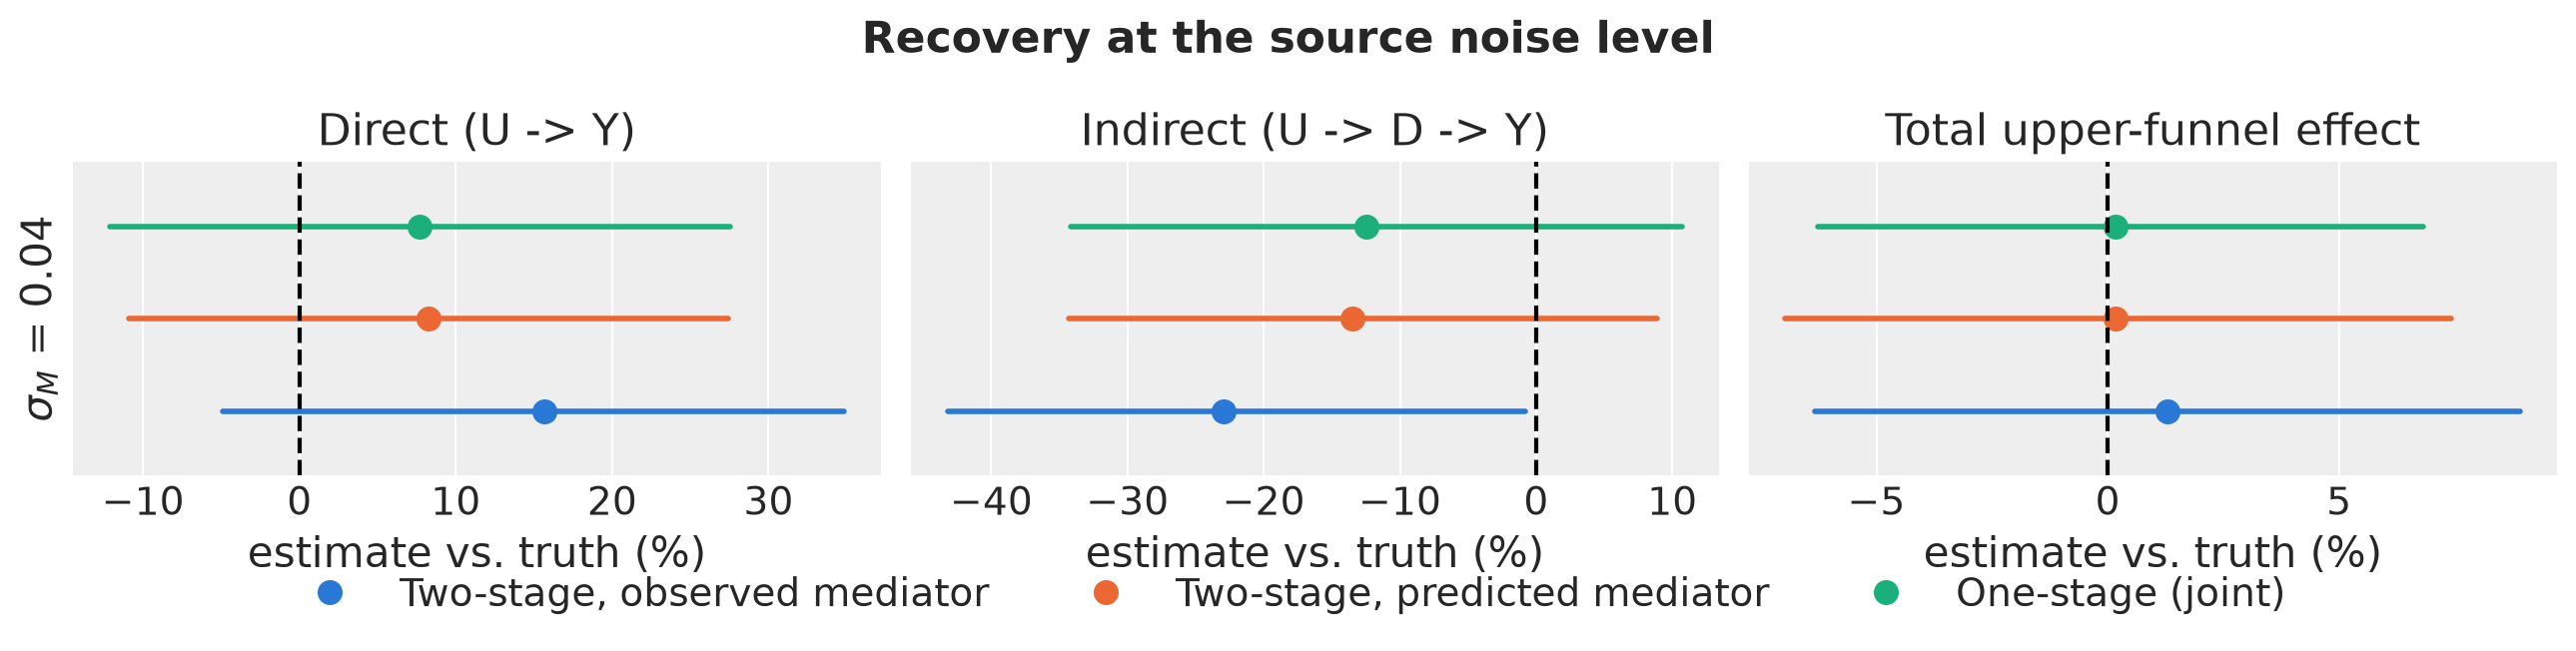

In [18]:
def plot_recovery(summaries: dict, title: str):
    """Forest plot of relative error, one row per setting and one column per path."""
    settings = list(summaries)
    fig, axes = plt.subplots(
        nrows=len(settings),
        ncols=len(PATHS),
        figsize=(FIG_WIDTH * 1.3, 1.6 + 1.5 * len(settings)),
        sharex="col",
        squeeze=False,
    )
    for i, setting in enumerate(settings):
        table = summaries[setting].set_index(["model", "path"])
        for j, path in enumerate(PATHS):
            ax = axes[i, j]
            for k, model in enumerate(MODELS):
                row = table.loc[(model, path)]
                rel = (
                    np.array([row["lower"], row["mean"], row["upper"]]) / row["truth"]
                    - 1
                )
                ax.plot(
                    rel[[0, 2]] * 100, [k, k], color=MODEL_COLORS[model], linewidth=2
                )
                ax.plot(
                    rel[1] * 100,
                    k,
                    "o",
                    color=MODEL_COLORS[model],
                    markersize=8,
                    label=MODEL_LABELS[model],
                )
            ax.axvline(0, color=COLOR_TRUE, linestyle="--", linewidth=1.5)
            ax.set(yticks=[], ylim=(-0.7, len(MODELS) - 0.3))
            if i == 0:
                ax.set_title(PATH_LABELS[path])
            if j == 0:
                ax.set_ylabel(setting)
            if i == len(settings) - 1:
                ax.set_xlabel("estimate vs. truth (%)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=len(MODELS),
        bbox_to_anchor=(0.5, -0.04),
    )
    fig.suptitle(title, fontsize=16, fontweight="bold")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    return fig


summaries = {0.04: summarize(results[0.04]["effects"], truth)}
plot_recovery(
    {r"$\sigma_M$ = 0.04": summaries[0.04]}, "Recovery at the source noise level"
);

**Caption:** Mean-over-time direct, indirect, and total upper-funnel contribution for each model, relative to the truth (dashed line at 0%). Dots are posterior means; bars are 94% intervals.

In [19]:
def format_summary(table):
    out = table.assign(model=table["model"].map(MODEL_LABELS)).set_index(
        ["model", "path"]
    )
    return out[
        ["truth", "mean", "lower", "upper", "bias", "width", "covers"]
    ].style.format(
        {
            "truth": "{:.3f}",
            "mean": "{:.3f}",
            "lower": "{:.3f}",
            "upper": "{:.3f}",
            "bias": "{:+.0%}",
            "width": "{:.0%}",
        }
    )


format_summary(summaries[0.04])

At the source noise level, the predicted-mediator and one-stage models agree to within one percentage point on every path. Both understate the indirect effect by 12 to 13%, and both intervals contain the truth.

The observed-mediator model is the outlier. It understates the indirect effect by 23%, and its interval (0.113 to 0.197) misses the true value of 0.199. The missing credit goes to the direct path (+16%). This is the errors-in-variables problem: stage 2 regresses sales on a noisy reading of demand, and noise in a regressor pulls its estimated effect toward zero.

All three models get the total within 1%, with intervals 13 to 15% of the truth wide. Splitting the effect into paths is the hard part.

At $\sigma_M = 0.04$, 90% of the relevant mediator variation is signal, so fitting jointly or in two stages makes little difference here. Next we make the mediator noisier.

## Noise sweep

Now we turn the dial. Demand, sales, and every true effect stay fixed; only the measurement of lower-funnel demand gets noisier.

In [20]:
for sigma_m in sigma_grid[1:]:
    results[sigma_m] = fit_all(data_at(sigma_m))
    summaries[sigma_m] = summarize(results[sigma_m]["effects"], truth)

pd.concat({sigma_m: diagnostics(results[sigma_m]) for sigma_m in sigma_grid[1:]})

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_baseline, mediator_parent_coef, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_baseline, mediator_parent_coef, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


divergences  max r_hat  min ess_bulk
    model                                                              
0.1 stage 1                                  0       1.01         503.0
    Two-stage, observed mediator             0       1.01         493.0
    Two-stage, predicted mediator            0       1.01         397.0
    One-stage (joint)                        0       1.01         701.0
0.2 stage 1                                  0       1.01         824.0
    Two-stage, observed mediator             0       1.01         576.0
    Two-stage, predicted mediator            0       1.01         487.0
    One-stage (joint)                        1       1.01         464.0

/var/folders/k2/hd2rrq590r9cmwy8cymlr5xw0000gq/T/ipykernel_67070/1101141033.py:49: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0.03, 1, 1))


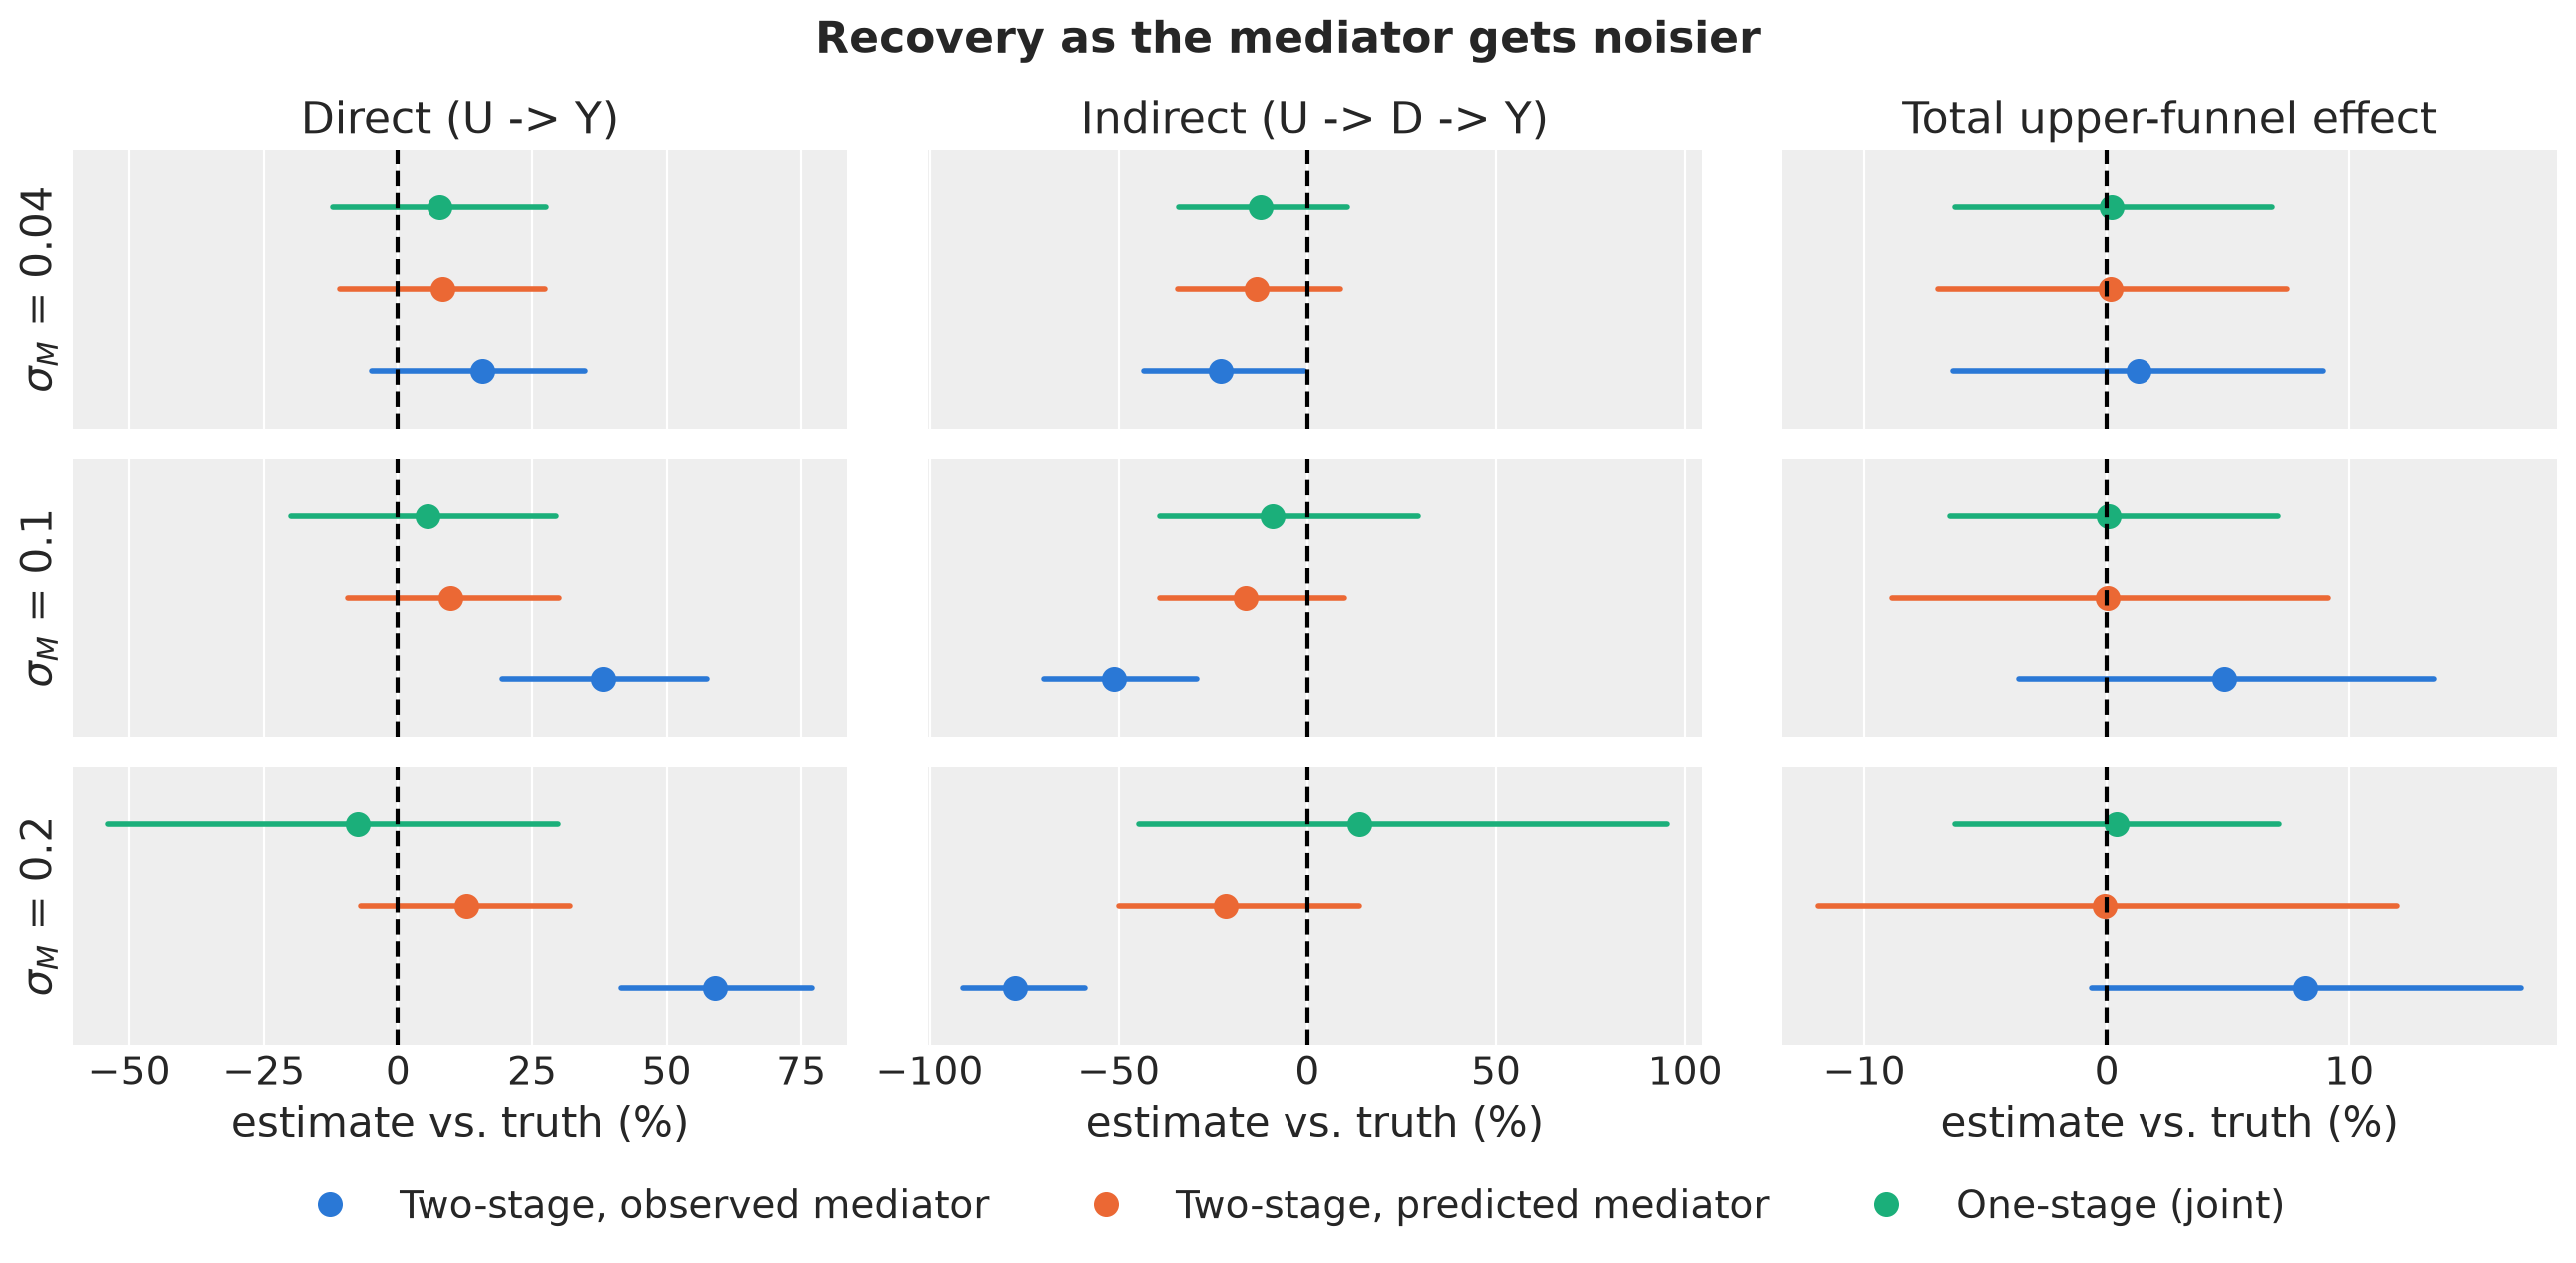

In [21]:
plot_recovery(
    {rf"$\sigma_M$ = {s}": summaries[s] for s in sigma_grid},
    "Recovery as the mediator gets noisier",
);

**Caption:** Relative error of each model's mean-over-time direct, indirect, and total effect (rows: mediator noise $\sigma_M$; columns: path). Dots are posterior means, bars 94% intervals, dashed line the truth.

In [22]:
sweep = pd.concat({s: summaries[s] for s in sigma_grid}, names=["sigma_M"]).reset_index(
    level=0
)
sweep.assign(model=sweep["model"].map(MODEL_LABELS)).pivot_table(
    index=["path", "model"], columns="sigma_M", values=["bias", "width"]
).style.format("{:+.0%}")

The observed-mediator model, the common approach, gets more wrong without getting less sure. Its indirect effect falls from 23% to 51% to 77% below the truth, its direct effect climbs to +59%, and its intervals stay about as wide as before (indirect: 42% to 32%). The noisier the signal, the more of the funnel effect it hands to the direct path. At $\sigma_M = 0.2$ even its total is off by +8%.

The predicted-mediator model removes most of that attenuation. Its indirect effect is still 13 to 22% too low, because stage 2 plugs the stage-1 estimate $\hat D$ into a saturating curve as if it were exact. Its total stays unbiased, and its total interval widens from 14% to 24% of the truth.

The one-stage model's split becomes uncertain as the noise grows. The indirect interval widens from 45% to 68% to 140% of the truth, and the point estimate moves (−12%, −9%, +14%) while the interval keeps covering the truth. Its total does not move: 0% bias and 13% width at every noise level.

That last result is the clearest difference between fitting jointly and fitting in two stages. The joint model keeps the trade-off between the two paths: sales fix their sum, so a draw that gives more to one path gives less to the other, and the total stays tight. The appendix shows this in detail. The replication study below checks how far the narrower interval can be trusted.

### How noisy is your signal?

The size of the common approach's bias depends on the reliability computed in the data section, and that calculation needs the latent demand $D$. With real data you never observe $D$. The one-stage model, though, estimates both the demand equation and the measurement noise $\sigma_M$, so it can estimate the reliability: the variation of demand that does not come from upper spend, divided by that same variation plus $\sigma_M^2$. Here is the estimate next to the true value.

In [23]:
def estimated_reliability(res):
    """One-stage estimate of the signal's reliability, one value per posterior draw."""
    hub, lift = one_stage_mediator(res["fits"]["one_stage"], res["frame"])
    other_var = (hub - lift).var(axis=1)
    sigma = flat(res["fits"]["one_stage"].idata, "mediator_measurement_sigma")
    return other_var / (other_var + sigma**2)


rows = []
for s in sigma_grid:
    rel = estimated_reliability(results[s])
    lo, hi = np.quantile(rel, [0.03, 0.97])
    rows.append(
        {
            "sigma_M": s,
            "true reliability": residual_var / (residual_var + s**2),
            "estimated": rel.mean(),
            "lower": lo,
            "upper": hi,
        }
    )
pd.DataFrame(rows).set_index("sigma_M").style.format("{:.0%}")

,true reliability,estimated,lower,upper
sigma_M,,,,
0.040000,90%,87%,84%,90%
0.100000,60%,54%,42%,64%
0.200000,27%,20%,9%,33%


The one-stage model's estimate is close to the truth at every noise level, slightly on the low side: 87% against 90%, 54% against 60%, and 20% against 27%, with intervals that contain the true value. You can run the same check on real data. A low estimated reliability warns that the common approach will understate the funnel effect and credit the difference to the direct path. The check relies on the one-stage model's own assumptions, so treat it as a warning sign rather than a measurement.

## Interval coverage over replications

One dataset tells us whether an interval happened to contain the truth, not how often it does. We repeat the comparison on 20 fresh datasets at $\sigma_M = 0.2$, with the same drivers and true effects and new sales and measurement noise each time. A calibrated 94% interval contains the truth in about 94% of replications. With 20 replications, each coverage figure has a simulation error of about ±5 percentage points.

Coverage alone cannot tell a calibrated interval from one that is too wide, because a too-wide interval also covers. So the table also compares each model's **typical error**, how far its estimate usually lands from the truth (root mean square, relative to the truth), with its **claimed error**, the error its own 94% intervals imply if the posterior is roughly normal. When the two match, the interval is calibrated. A claimed error below the typical error means the model is overconfident.

```{note}
This section fits 4 models per replication. We use fewer posterior draws here to keep the run time reasonable.
```

In [24]:
n_reps = 20
sigma_rep = 0.2

with gen.model:
    idata_reps = pm.sample_prior_predictive(
        draws=n_reps, var_names=["y_original_scale", "mediator_hub"], random_seed=rng
    )
y_reps = (
    idata_reps["prior"]["y_original_scale"]
    .to_numpy()
    .reshape(n_reps, n_dates, -1)[..., 0]
)
demand_reps = (
    idata_reps["prior"]["mediator_hub"].to_numpy().reshape(n_reps, n_dates, -1)[..., 0]
)

rep_rows = []
for r in range(n_reps):
    demand_r = demand_reps[r, l_max:]
    frame_r = df.assign(
        y_obs=y_reps[r, l_max:],
        lower_spend=stats.truncnorm.rvs(
            a=-demand_r / sigma_rep,
            b=np.inf,
            loc=demand_r,
            scale=sigma_rep,
            random_state=rng,
        ),
    )
    res_r = fit_all(frame_r, draws=500)
    rep_rows.append(summarize(res_r["effects"], truth).assign(rep=r))

replications = pd.concat(rep_rows, ignore_index=True)

Sampling: [y]


NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_baseline, mediator_parent_coef, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


...

NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_baseline, mediator_parent_coef, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


In [25]:
z_94 = stats.norm.ppf(0.97)


def coverage_table(replications):
    """Coverage, bias, and typical vs claimed error per path and model."""
    table = (
        replications.assign(model=replications["model"].map(MODEL_LABELS))
        .groupby(["path", "model"])
        .agg(
            coverage=("covers", "mean"),
            mean_bias=("bias", "mean"),
            typical_error=("bias", lambda b: np.sqrt(np.mean(b**2))),
            claimed_error=("width", lambda w: w.mean() / (2 * z_94)),
        )
    )
    return table.style.format(
        {
            "coverage": "{:.0%}",
            "mean_bias": "{:+.0%}",
            "typical_error": "{:.1%}",
            "claimed_error": "{:.1%}",
        }
    )


coverage_table(replications)

**Caption:** Over 20 replications at $\sigma_M = 0.2$: share of 94% intervals containing the true mean-over-time effect (coverage), average relative bias, typical error, and claimed error, both relative to the truth.

The observed-mediator model never covers the truth on the direct or indirect path (0 of 20), with average biases of +53% and −76%. Its typical errors are five to eight times what its intervals claim. The failure on the single dataset above was systematic.

The predicted-mediator and one-stage models are about equally accurate on every path: their typical errors are within one percentage point of each other. They differ in what they claim. On the split, the predicted-mediator model claims about half of its typical error (10.3% against 20.6% on the direct effect, 19.8% against 34.0% on the indirect), so its intervals cover only 65% and 70% of the time. The one-stage model's claims come closer (18.0% against 21.6%, 28.2% against 34.5%), with 90% and 85% coverage.

On the total, the two models make almost the same estimate, with a typical error of 4.7%. The one-stage interval claims 3.7%, a bit too little, and covers the truth 16 times out of 20. The predicted-mediator interval claims 7.2%, too much, and covers it all 20 times. Neither is exactly calibrated; the one-stage interval is narrower and errs on the confident side.

## Reverse scenario: when the signal drives sales

So far the data came from the one-stage model. Now we flip it. Suppose the lower-funnel series is a lever that drives sales by itself, such as lower-funnel spend: sales respond to what was spent, including the part that demand does not explain (bid changes, pacing, budget shocks). Then

$$
\mu_t = \alpha + f_{\text{direct}}(U_t) + f_{l\to y}(M_t),
$$

and the true indirect effect of upper spend is $f_{l\to y}(M) - f_{l\to y}(M - \Delta)$. Here the common approach, the observed-mediator model, is correctly specified and the two latent-demand models are not. We keep $\sigma_M = 0.2$, where the forward scenario separated the models most, and reuse the same true parameters.

In [26]:
sigma_rev = 0.2
lower_rev = measure_demand(sigma_rev)
lift_true = (df["demand_true"] - df["demand_no_upper_true"]).to_numpy()


def true_lower_path(x):
    return lower_path(
        np.asarray(x),
        true["adstock_contribution_alpha"].reshape(1),
        true["sat_contribution_lam"].reshape(1),
        true["sat_contribution_beta"].reshape(1),
    )[0]


noise_rev = rng.normal(0, float(true["y_sigma"]), size=len(df))
df_rev = df.assign(
    lower_spend=lower_rev,
    y_obs=float(true["intercept_contribution"])
    + df["direct_true"]
    + true_lower_path(lower_rev)
    + noise_rev,
)
truth_rev = {
    "direct": df["direct_true"].to_numpy(),
    "indirect": true_lower_path(lower_rev) - true_lower_path(lower_rev - lift_true),
}
truth_rev["total"] = truth_rev["direct"] + truth_rev["indirect"]

results_rev = fit_all(df_rev)
summary_rev = summarize(results_rev["effects"], truth_rev)
diagnostics(results_rev)

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_baseline, mediator_parent_coef, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


,divergences,max r_hat,min ess_bulk
model,,,
stage 1,0,1.01,824.0
"Two-stage, observed mediator",0,1.00,726.0
"Two-stage, predicted mediator",0,1.01,365.0
One-stage (joint),0,1.01,429.0


/var/folders/k2/hd2rrq590r9cmwy8cymlr5xw0000gq/T/ipykernel_67070/1101141033.py:49: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0.03, 1, 1))


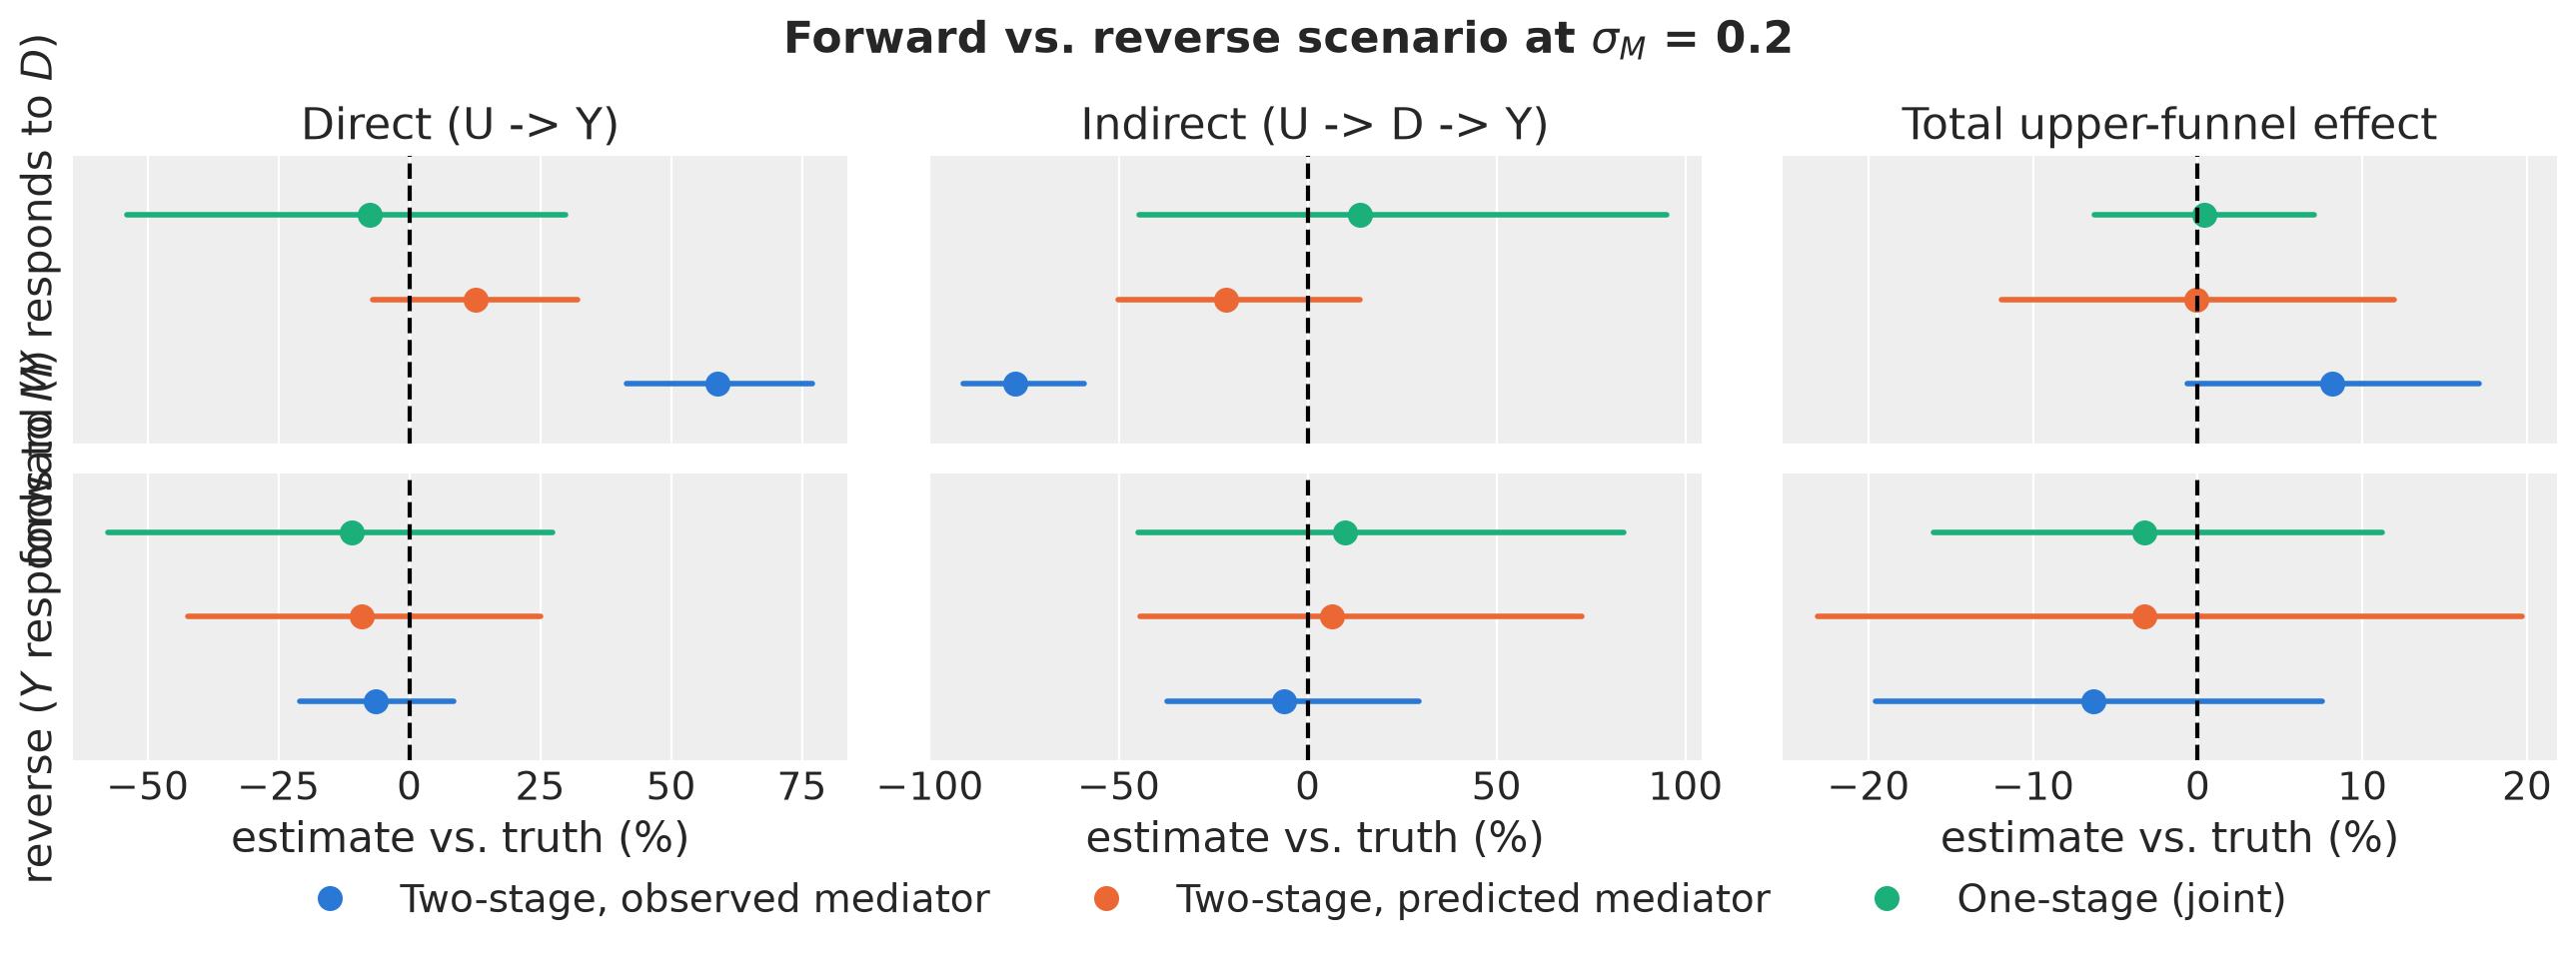

In [27]:
plot_recovery(
    {
        r"forward ($Y$ responds to $D$)": summaries[sigma_rev],
        r"reverse ($Y$ responds to $M$)": summary_rev,
    },
    rf"Forward vs. reverse scenario at $\sigma_M$ = {sigma_rev}",
);

**Caption:** Relative error of each model under the forward data generating process (target responds to latent demand) and the reverse one (target responds to the observed series), both at $\sigma_M = 0.2$.

In [28]:
format_summary(summary_rev)

On this dataset the observed-mediator model is correctly specified and does well. Every path is within 6% of the truth, every interval covers it, and it has the narrowest intervals for the split (29% direct, 67% indirect).

The two latent-demand models are now misspecified, but they stay within 11% of the truth and every interval covers it. They pay in width: their direct-effect intervals are two to three times wider than the correct model's (67% and 85% against 29%). The one-stage total interval is as narrow as the correct model's (27%).

### Replications

One dataset is not enough to back a fairness claim, so we repeat the reverse scenario on 20 fresh datasets, as in the forward scenario. Each replication draws new measurement noise and new sales noise. Because sales now respond to the observed series, the true indirect effect changes slightly from one replication to the next.

In [29]:
rev_rows = []
for r in range(n_reps):
    lower_r = stats.truncnorm.rvs(
        a=-demand / sigma_rev,
        b=np.inf,
        loc=demand,
        scale=sigma_rev,
        random_state=rng,
    )
    frame_r = df.assign(
        lower_spend=lower_r,
        y_obs=float(true["intercept_contribution"])
        + df["direct_true"]
        + true_lower_path(lower_r)
        + rng.normal(0, float(true["y_sigma"]), size=len(df)),
    )
    truth_r = {
        "direct": df["direct_true"].to_numpy(),
        "indirect": true_lower_path(lower_r) - true_lower_path(lower_r - lift_true),
    }
    truth_r["total"] = truth_r["direct"] + truth_r["indirect"]
    res_r = fit_all(frame_r, draws=500)
    rev_rows.append(summarize(res_r["effects"], truth_r).assign(rep=r))

replications_rev = pd.concat(rev_rows, ignore_index=True)
coverage_table(replications_rev)

NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_baseline, mediator_parent_coef, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_baseline, mediator_parent_coef, mediator_measurement_sigma]


...

NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_baseline, mediator_parent_coef, mediator_measurement_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, adstock_contribution_alpha, sat_contribution_lam, sat_contribution_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_contribution_alpha, adstock_hub_alpha, sat_hub_lam, sat_hub_beta, mediator_parent_coef, mediator_baseline, sat_contribution_lam, sat_contribution_beta, adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma, mediator_measurement_sigma]


**Caption:** Over 20 replications of the reverse scenario at $\sigma_M = 0.2$, with the same columns as the forward coverage table.

The replications confirm the single dataset. The observed-mediator model, now correctly specified, is the most accurate on the split: its typical error is 5.3% on the direct effect against 14 to 15% for the latent-demand models, and 22% on the indirect effect against 27 to 29%. On the total, all three models are about equally accurate, with typical errors of 8.5% to 10.8%.

The two latent-demand models are misspecified, yet their average biases stay within 7% and their intervals for the split cover the truth 90 to 100% of the time. Their intervals are wider, and on the split they are calibrated or slightly cautious rather than overconfident.

The one-stage total interval is again a little too narrow (75% coverage; claimed error 6.3% against a typical 8.7%), but so is the correctly specified model's (80%; 6.6% against 8.5%). The narrow total interval seems to come from this setup rather than from fitting jointly.

So the two mistakes cost different things. Treating the signal as the cause when sales respond to demand gave biased answers, with intervals too narrow to flag the problem: 0 of 20 intervals for the split covered the truth in the forward scenario. Treating sales as responding to demand when the signal drives them gave less precise answers that still contained the truth.

## When to use which

Start with what drives sales. A simple test: if you doubled the lower-funnel series, would sales move? Lower-funnel spend usually passes. Branded search volume usually fails, because nobody buys search volume; it is a symptom of people being in the market.

If the series passes the test, it is a lever, and the common approach is correctly specified. Its posterior splits into two independent pieces, so fitting in one stage or two gives the same answer, and in the reverse scenario it was the most accurate model on the split. Use whichever is easier to run.

If the series fails the test, it is a reading of demand. The common approach then understates the funnel effect and credits the difference to the direct path, more so the noisier the reading, and its intervals do not widen to warn you. Its total stayed within 8% of the truth here, so a decision about total upper-funnel spend is roughly safe. Any decision that depends on how much of the effect runs through the funnel is not. Model demand as a latent variable instead, and use the one-stage model's reliability estimate to judge how much the choice matters on your data.

Among the latent-demand models, fitting in one stage or two matters less. Both were about equally accurate. The joint model reported its uncertainty on the split more accurately, while the two-stage version claimed about half of its typical error. When the reliability is high, the two agree and the modular two-stage workflow is fine.

If you cannot tell whether the series is a lever or a reading, the two scenarios point toward modeling demand. Getting that assumption wrong cost precision; getting the opposite assumption wrong cost correctness.

## Caveats

- All results come from one synthetic world with a single upper-funnel channel, 122 weeks, and fixed true parameters. The forward data are sampled from the one-stage model itself; the reverse scenario is the check against this.
- In practice a lower-funnel series is often both a reading of demand and a lever, for example spend that follows demand and also brings clicks. We test only the two pure cases.
- Coverage comes from 20 replications per scenario, so differences of about 10 percentage points are within simulation noise.
- The predicted-mediator model plugs in the stage-1 posterior mean of demand. Refitting stage 2 for many stage-1 draws would carry more stage-1 uncertainty into the split, at several times the cost.
- Implementations of the common approach that make the signal $\to$ sales path linear also ignore diminishing returns through the funnel. We did not test that variant.
- With a single lever there is no budget to allocate. Comparing budget decisions needs several channels, as in {ref}`mmm_funnel_mueffect_advanced`.

## Appendix: why the joint model's total is tighter

The joint posterior can differ from a two-stage one in two ways. Sales data can sharpen the mediator equation itself, and the joint posterior can learn correlations between the parameters of the two stages. We check each.

### Do sales inform the mediator equation?

We compare the posterior standard deviation of each mediator-equation parameter in stage 1 (lower-funnel data only) with the joint model (lower-funnel data and sales). A ratio below 1 means sales added information.

In [30]:
mediator_params = [
    "mediator_baseline",
    "mediator_parent_coef",
    "adstock_hub_alpha",
    "sat_hub_lam",
    "sat_hub_beta",
    "mediator_measurement_sigma",
]
sd_ratio = pd.DataFrame(
    {
        s: {
            p: float(results[s]["fits"]["one_stage"].idata.posterior[p].std())
            / float(results[s]["stage1"].posterior[p].std())
            for p in mediator_params
        }
        for s in sigma_grid
    }
)
sd_ratio.columns.name = "sigma_M"
sd_ratio.style.format("{:.2f}")

sigma_M,0.040000,0.100000,0.200000
mediator_baseline,1.01,1.05,0.90
mediator_parent_coef,1.00,1.02,1.08
adstock_hub_alpha,1.00,0.96,0.79
sat_hub_lam,0.99,1.05,1.13
sat_hub_beta,0.96,0.81,0.70
mediator_measurement_sigma,1.04,1.01,0.97


At $\sigma_M = 0.04$ all ratios are close to 1: with a clean measurement, sales add almost nothing to what lower-funnel data already say. At $\sigma_M = 0.2$, sales narrow down the size and timing of upper spend's lift on demand (`sat_hub_beta` 0.70, `adstock_hub_alpha` 0.79), while `sat_hub_lam` and `mediator_parent_coef` get slightly wider (1.13 and 1.08). The gain is modest, so this mechanism explains only a small part of the gap.

### Cross-stage correlation

The second mechanism is one that a two-stage fit cannot reproduce, even with paired draws. In the joint posterior, a draw that gives more credit to the mediated path gives less to the direct path, because both are learned from the same sales data. In a two-stage fit, the lift $\Delta$ comes from a posterior that never saw sales, so it varies independently of stage 2's direct effect.

To test this, we take the joint posterior and shuffle the mediator-equation draws (demand and lift) relative to the outcome-equation draws. Shuffling keeps every marginal distribution and removes only the dependence between the stages. If that dependence is what keeps the joint total tight, the shuffled ("decoupled") total should widen.

In [31]:
def decoupled_effects(res, seed=0):
    """Joint posterior with mediator-equation draws shuffled across samples."""
    joint = res["fits"]["one_stage"]
    hub, lift = one_stage_mediator(joint, res["frame"])
    perm = np.random.default_rng(seed).permutation(hub.shape[0])
    return path_effects(joint, hub[perm], lift[perm])


def path_correlation(effects):
    """Posterior correlation between mean direct and mean indirect effect."""
    return float(
        np.corrcoef(effects["direct"].mean(axis=1), effects["indirect"].mean(axis=1))[
            0, 1
        ]
    )


rows = []
for s in sigma_grid:
    effects = dict(results[s]["effects"])
    effects["one_stage_decoupled"] = decoupled_effects(results[s])
    table = summarize(effects, truth).set_index(["model", "path"])
    for model, eff in effects.items():
        rows.append(
            {
                "sigma_M": s,
                "model": MODEL_LABELS.get(model, "One-stage, decoupled"),
                "corr(direct, indirect)": path_correlation(eff),
                "total width": table.loc[(model, "total"), "width"],
            }
        )
correlation_table = pd.DataFrame(rows).pivot_table(
    index="model", columns="sigma_M", values=["corr(direct, indirect)", "total width"]
)
correlation_table.style.format("{:.2f}")

In the joint posterior, the direct and indirect effects are strongly negatively correlated, and more so as the mediator gets noisier (−0.87, −0.91, −0.97). Sales fix their sum, and a noisy mediator says little about the split, so the draws trade one path against the other while the total stays put.

Decoupling weakens the correlation (−0.74 at $\sigma_M = 0.2$) and widens the total interval from 13% to 22% and then 38% of the truth. At $\sigma_M = 0.04$ it barely matters (13% to 15%), as expected when the stages are nearly independent. The decoupled total ends up wider than either two-stage total because the joint model is less certain about each path on its own.

The two-stage models sit in between. Their correlations weaken with noise (−0.61 and −0.49 at $\sigma_M = 0.2$) and their total intervals widen (18% and 24%).

Cross-stage correlation is therefore the main mechanism. Paired draws carry stage-1 uncertainty into a two-stage answer, but they cannot carry the dependence between stage-1 and stage-2 parameters that sales data create, because stage 1 never sees sales.

In [32]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor

Last updated: Mon, 12 Oct 2026

Python implementation: CPython
Python version       : 3.12.15
IPython version      : 9.15.0

pymc_marketing: 1.2.0
pytensor      : 3.3.2

arviz         : 1.2.0
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pydantic      : 2.13.4
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
pytensor      : 3.3.2
scipy         : 1.15.3
xarray        : 2026.4.0

Watermark: 2.6.0

